# Computation of Effective area

## Summary
- Load selected gamma rays and all gamma rays from MC
- Bins : 20 in Energy from 1 to 100 GeV, 10 in theta from 0 to 60° (Duan)
- Raffiner les bins par endroit? 

In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

## Load MC data

In [2]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath = dirDir + "data/"
filename = dataDir + "DmlNtup_gamma_part000_TQ_FullSel.root"

# Find all matching ROOT files : from 1 GeV to 100 GeV
files = sorted(glob.glob(dataDir + "DmlNtup_gamma_part*_TQ_FullSel.root"))

# Pass the list of files to RDataFrame
rdf = ROOT.RDataFrame("DmlNtup", files)

# Apply cut on LET
rdf = rdf.Filter("theta_True < 60")

# Extract only desired columns
df = rdf.AsNumpy(["tt_ekin", "tt_bgoTotalEcorr_GeV", "theta_True", "tt_isHET", "tt_isLET"])
df = pd.DataFrame(df)

## Necessary transformations

In [3]:
df['Etrue'] = df['tt_ekin'] * 1e-3
df['Erec'] = df['tt_bgoTotalEcorr_GeV']

df['theta_True_deg']= df['theta_True']
df['theta_True'] = np.deg2rad(df['theta_True'])
df['cosTheta'] = np.cos(df['theta_True'])

## TODO : load filtered data

In [4]:
# Load filtered data here
dfLET = pd.read_csv(dataPath + "MC_let_filtered_energy.csv")
dfLET = dfLET[dfLET['tt_isHET'] == 1] # /!\ change condition here to choose trigger type

dfLET['Etrue'] = dfLET['tt_ekin'] * 1e-3
dfLET = dfLET[dfLET['Etrue'] <= 100]
dfLET['Erec'] = dfLET['tt_bgoTotalEcorr_GeV']

dfLET['theta_True_deg']= dfLET['theta_True']
dfLET['theta_True'] = np.deg2rad(dfLET['theta_True'])
dfLET['cosTheta'] = np.cos(dfLET['theta_True'])

## Create bins

In [5]:
Emin = 1
Emax_LET = 100
n_E_bins_LET = 20

cos_theta_min = 0.5
cos_theta_max = 1
n_theta_bins = 10

E_bins_edge_LET = np.logspace(np.log10(Emin), np.log10(Emax_LET), n_E_bins_LET + 1)
E_bins_center_LET = np.sqrt(E_bins_edge_LET[:-1] * E_bins_edge_LET[1:])

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

In [6]:
Emax_HET = 1e4
n_E_bins_HET = 40

E_bins_edge_HET = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_E_bins_HET + 1)
E_bins_center_HET = np.sqrt(E_bins_edge_HET[:-1] * E_bins_edge_HET[1:])

### Bin the MC data

In [7]:
# Assign bin indices
df['E_bin_LET'] = pd.cut(df['Etrue'], bins=E_bins_edge_LET, labels=False, include_lowest=True)
df['E_bin_HET'] = pd.cut(df['Etrue'], bins=E_bins_edge_HET, labels=False, include_lowest=True)
df['cos_theta_bin'] = pd.cut(df['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)

# Drop rows that fall outside the bins (e.g., NaN bin index)
df = df.dropna(subset=['E_bin_LET', 'E_bin_HET' , 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning

# Make sure bin indices are integers
df['E_bin_LET'] = df['E_bin_LET'].astype(int)
df['E_bin_HET'] = df['E_bin_HET'].astype(int)
df['cos_theta_bin'] = df['cos_theta_bin'].astype(int)

### Bin the LET data

In [8]:
dfLET['E_bin_LET'] = pd.cut(dfLET['Etrue'], bins=E_bins_edge_LET, labels=False, include_lowest=True)
dfLET['cos_theta_bin'] = pd.cut(dfLET['cosTheta'], bins=theta_bins_edge, labels=False, include_lowest=True)
dfLET = dfLET.dropna(subset=['E_bin_LET', 'cos_theta_bin']).copy() # Copy to avoid SettingWithCopyWarning
dfLET['E_bin_LET'] = dfLET['E_bin_LET'].astype(int)
dfLET['cos_theta_bin'] = dfLET['cos_theta_bin'].astype(int)

## Bin df_results

In [9]:
# Group original events (denominator)
total_counts = (
    df.groupby(['E_bin_LET', 'cos_theta_bin'])
    .size()
    .rename('total')
)

# Group accepted events (numerator)
accepted_counts = (
    dfLET.groupby(['E_bin_LET', 'cos_theta_bin'])
    .size()
    .rename('accepted')
)

# Join and compute acceptance and effarea
r = 1.38*1e2 # cm
df_results_geom = 37.59 * 1e4 # cm^2 sr
eff_area_geom = (np.pi)*(r**2)
df_results = pd.concat([accepted_counts, total_counts], axis=1).fillna(0)
df_results['acceptance'] = df_results['accepted'] * df_results_geom / df_results['total']
df_results['effArea'] = df_results['accepted'] * eff_area_geom / df_results['total']
# Optional: reset index if you want a flat DataFrame
df_results = df_results.reset_index()

print(df_results)
# If you want to save:
#df_results.to_csv(dataPath + "df_results_LET.csv", index=False)


     E_bin_LET  cos_theta_bin  accepted   total  acceptance   effArea
0            0              8       1.0   75856    4.955442  0.788711
1            1              2       1.0   86703    4.335490  0.690039
2            1              3       4.0   98786   15.220780  2.422549
3            1              4       2.0  109965    6.836721  1.088137
4            1              5       3.0  120702    9.342844  1.487013
..         ...            ...       ...     ...         ...       ...
195          0              7       0.0   69360    0.000000  0.000000
196          0              9       0.0   81085    0.000000  0.000000
197          1              0       0.0   62222    0.000000  0.000000
198          1              1       0.0   75458    0.000000  0.000000
199          2              0       0.0   71785    0.000000  0.000000

[200 rows x 6 columns]


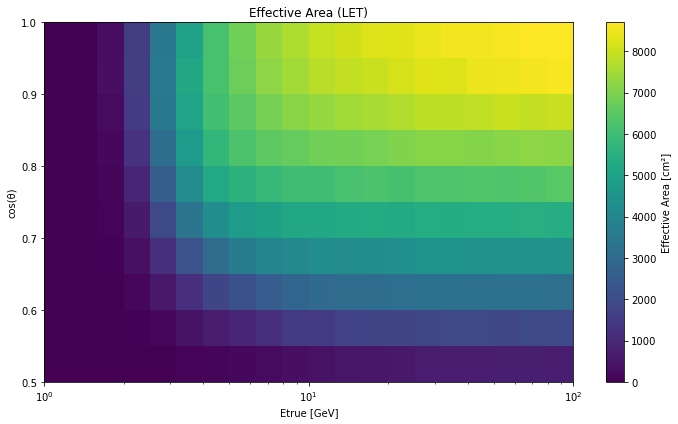

In [10]:
# Create 2D array of df_results values: shape (n_theta_bins, n_E_bins)
df_results_grid = df_results.pivot(index='cos_theta_bin', columns='E_bin_LET', values='effArea').values


fig, ax = plt.subplots(figsize=(10, 6))
mesh = ax.pcolormesh(
    E_bins_edge_LET, theta_bins_edge, df_results_grid,
    shading='auto', cmap='viridis'
)

# Log scale for E axis if needed
ax.set_xscale('log')

# Labels and title
ax.set_xlabel("Etrue [GeV]")
ax.set_ylabel("cos(θ)")
ax.set_title("Effective Area (LET)")
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("Effective Area [cm²]")

plt.tight_layout()
plt.show()

## Explo : which MC photon is which trigger?

In [11]:
# Plot Energy histogram of df which belong to neither LET nor HET

rdf = rdf.Define('Etrue', 'tt_ekin/1.e3')

rdf_none = rdf.Filter("tt_isLET == 0").Filter("tt_isHET == 0")
rdf_LET = rdf.Filter("tt_isLET == 1")
rdf_LETnonHET = rdf.Filter("tt_isLET == 1").Filter("tt_isHET == 0")
rdf_HETnonLET = rdf.Filter("tt_isLET == 0").Filter("tt_isHET == 1")
rdf_HET = rdf.Filter("tt_isHET == 1")

h_none = rdf_none.Histo1D(("hNone", "; Energy [GeV]; Counts",30,1, 100), 'Etrue')
h_LET = rdf_LET.Histo1D(("hLET", "; Energy [GeV]; Counts", 30,1, 100), 'Etrue')
h_LETnonHET = rdf_LETnonHET.Histo1D(("hLETnonHET", "; Energy [GeV]; Counts", 30,1, 100), 'Etrue')
h_HETnonLET = rdf_HETnonLET.Histo1D(("hHETnonLET", "; Energy [GeV]; Counts", 30,1, 100), 'Etrue')
h_HET = rdf_HET.Histo1D(("hHET", "; Energy [GeV]; Counts", 30,1, 100), 'Etrue')

In [12]:
# Convert to TH1 to keep them alive
# h1_none = h_none.GetValue()
# h1_LET = h_LET.GetValue()
# h1_LETnonHET = h_LETnonHET.GetValue()
# h1_HETnonLET = h_HETnonLET.GetValue()
# h1_HET = h_HET.GetValue()

# Style
h_none.SetLineColor(ROOT.kBlack)
h_LET.SetLineColor(ROOT.kBlue)
h_LETnonHET.SetLineColor(ROOT.kCyan+1)
h_HETnonLET.SetLineColor(ROOT.kRed)
h_HET.SetLineColor(ROOT.kMagenta)

h_none.SetMarkerStyle(1)
h_LET.SetMarkerStyle(1)
h_LETnonHET.SetMarkerStyle(1)
h_HETnonLET.SetMarkerStyle(1)
h_HET.SetMarkerStyle(1)

# Draw
ROOT.gStyle.SetOptStat(0)
c = ROOT.TCanvas()

h_none.SetStats(0)

h_none.Draw("HIST")
h_LET.Draw("HIST SAME")
h_LETnonHET.Draw("HIST SAME")
h_HETnonLET.Draw("HIST SAME")
h_HET.Draw("HIST SAME")


legend = ROOT.TLegend(0.6, 0.6, 0.89, 0.89)  # x1, y1, x2, y2

legend.AddEntry(h_none.GetPtr(), "None", "l")
legend.AddEntry(h_LET.GetPtr(), "LET", "l")
legend.AddEntry(h_LETnonHET.GetPtr(), "LET only", "l")
legend.AddEntry(h_HETnonLET.GetPtr(), "HET only", "l")
legend.AddEntry(h_HET.GetPtr(), "HET", "l")

legend.SetBorderSize(0)
legend.SetFillStyle(0)
legend.Draw("SAME")

c.SetLogy()
c.SetLogx()
c.Update()
c.Draw()